## Imports

In [40]:
from eval import tracs_rate_scenario, compute_argoverse2_metrics
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from os import makedirs
from json import dump
from tracs.alignment import Alignment
import torch
from av2.datasets.motion_forecasting.eval import metrics
import tqdm

## Load data

In [2]:
data_root = Path("../dataset")
backbone = "DeMo"
number_of_tests = 10
prediction_path = data_root / f"{backbone}_submission.parquet"
backbone_metrics_path = data_root / f"{backbone}_metrics.parquet"
results_path = data_root / "results" / backbone

## Logic to test

In [3]:
logic = """
distance(vehicle) <- source("/star_map/distance/vehicle", Density).
speed <- source("/sensors/speed", Number).

landscape if distance(vehicle) > 5 and speed < 50.

landscape -> target("/landscape").
"""

tracs_metrics_path = results_path / str(hash(logic)) / "metrics.parquet"
gt_scores_path = results_path / str(hash(logic)) / "gt_scores.parquet"
makedirs(results_path / str(hash(logic)), exist_ok=True)

## Run tests

In [52]:
predictions = pd.read_parquet(prediction_path)
ground_truth = pd.read_parquet(data_root / "av2_mf_focal_test_annotations.parquet")

scenario_ids = []
hit_rates = []
gt_traj_diffs = []
for i, scenario_id in tqdm.tqdm(enumerate(predictions["scenario_id"].unique()), total=len(predictions["scenario_id"].unique())):
    gt_track = ground_truth[ground_truth["scenario_id"] == scenario_id].iloc[0]
    gt_track = np.array([gt_track["gt_trajectory_x"], gt_track["gt_trajectory_y"]]).T

    focal_predictions = predictions[predictions["scenario_id"] == scenario_id]
    focal_predictions = focal_predictions[focal_predictions["probability"] < 1.0]

    predicted_tracks = np.moveaxis(
        np.array(
            [[*focal_predictions["predicted_trajectory_x"]], 
            [*focal_predictions["predicted_trajectory_y"]]]
        ),
        source=[0, 1, 2], 
        destination=[2, 0, 1],
    )

    is_missed = metrics.compute_is_missed_prediction(predicted_tracks, gt_track)

    diff_x = np.diff(gt_track[:, 0])
    diff_y = np.diff(gt_track[:, 1])

    scenario_ids.append(scenario_id)
    hit_rates.append(1.0 - is_missed.mean())
    gt_traj_diffs.append(np.hstack([diff_x, diff_y]))

pd.DataFrame({"scenario_id": scenario_ids, "hit_rates": hit_rates, "gt_traj_diffs": gt_traj_diffs}).to_parquet("DeMo_alignment_train_data.parquet")

100%|██████████| 24984/24984 [03:30<00:00, 118.61it/s]


In [ ]:
ground_truth = pd.read_parquet(data_root / "av2_mf_focal_test_annotations.parquet")

contexts = []
hit_rates = []
for scenario_id in metrics["scenario_id"]: 
    ground_truth_traj = ground_truth[ground_truth["scenario_id"] == scenario_id].iloc[0]
    ground_truth_traj["x_traj"] = ground_truth_traj["gt_trajectory_x"]
    ground_truth_traj["y_traj"] = ground_truth_traj["gt_trajectory_y"]

    diff_x = np.diff(ground_truth_traj["x_traj"])
    diff_y = np.diff(ground_truth_traj["y_traj"])

    hit_rates.append(metrics[metrics["scenario_id"] == scenario_id]["hit_rate"].item())
    contexts.append(np.hstack([diff_x, diff_y]))

hit_rates = torch.tensor(np.vstack(hit_rates), dtype=torch.float)
contexts = torch.tensor(np.vstack(contexts), dtype=torch.float)

                             scenario_id  hit_rates
0   0000b329-f890-4c2b-93f2-7e2413d4ca5b   0.333333
1   0008c251-e9b0-4708-b762-b15cb6effc27   0.166667
2   0008eb72-8351-4356-8c24-08c10cf34175   0.166667
3   000a45e7-bded-43e7-970b-18c08cc86c2d   0.333333
4   000c5b17-084c-4268-8d49-0cb317458cee   0.166667
5   000ca346-11b5-406f-af1f-002fc67ef5c6   0.000000
6   000d3749-6867-4d89-8f24-7fd6f8cae807   0.166667
7   000f20cc-2507-4d6e-9490-73cf07e66eb3   0.333333
8   00105804-8330-4cff-9806-740499abad92   0.000000
9   001d0e50-1fac-44df-8ab4-493b0e3521f5   0.333333
10  001e759c-cc3e-4324-8bc5-1fc08754cefa   0.333333
11  001f3cc2-96f7-44ad-adbf-a893d77213c9   0.500000


ZeroDivisionError: division by zero

In [203]:
hit_rates = pd.read_parquet("DeMo_alignment_train_data.parquet")
X = np.vstack(hit_rates["hit_rates"])
C = np.vstack(hit_rates["gt_traj_diffs"])

X = torch.tensor(X, dtype=torch.float)
C = torch.tensor(C, dtype=torch.float)

alignment = Alignment(1, 100, 10, 118)
losses = alignment.fit(X, C, 100, 500)

Learning Alignment: 100%|██████████| 100/100 [02:55<00:00,  1.76s/epoch]


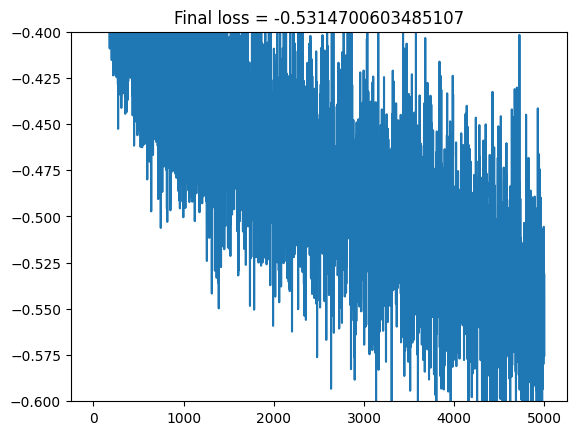

In [204]:
plt.plot(range(len(losses)), losses)
plt.ylim(-0.6, -0.4)
plt.title(f"Final loss = {losses[-1]}")
plt.show()

In [205]:
def get_worst(metrics_path: str, n_head=36):
    metrics_df = pd.read_parquet(metrics_path)
    print("before filtering:", len(metrics_df))
    # metrics_df = metrics_df[(metrics_df["is_missed_prediction1"]) & (
        # ~metrics_df["is_missed_prediction6"])]
    metrics_df = metrics_df[(~metrics_df["is_missed_prediction6"])]
    print("after filtering:", len(metrics_df))
    return metrics_df.sort_values("brier_minADE6", ascending=False).head(n_head)

worst = get_worst(backbone_metrics_path)

before filtering: 24984
after filtering: 21267


In [218]:
sorted_hit_rates = hit_rates.sort_values("hit_rates", ascending=False)
scenario = 0

ground_truth = pd.read_parquet(data_root / "av2_mf_focal_test_annotations.parquet")
ground_truth_traj = ground_truth[ground_truth["scenario_id"] == sorted_hit_rates.iloc[scenario]["scenario_id"]].iloc[0]
ground_truth_traj["x_traj"] = ground_truth_traj["gt_trajectory_x"]
ground_truth_traj["y_traj"] = ground_truth_traj["gt_trajectory_y"]

diff_x = np.diff(ground_truth_traj["x_traj"])
diff_y = np.diff(ground_truth_traj["y_traj"])

context = np.hstack([diff_x, diff_y])
context = torch.tensor(context, dtype=torch.float)

In [219]:
probs = alignment.prob(torch.linspace(0, 1, 1000)[torch.newaxis].T, context.repeat((1000, 1)))
pdf = probs.detach().numpy()
normalized_pdf = pdf / pdf.sum()
expectation = np.mean([normalized_pdf[i] * i for i in range(len(normalized_pdf))])
hit_rate = sorted_hit_rates.iloc[scenario]["hit_rates"]
print(hit_rate)
print(expectation)

1.0
0.64504457


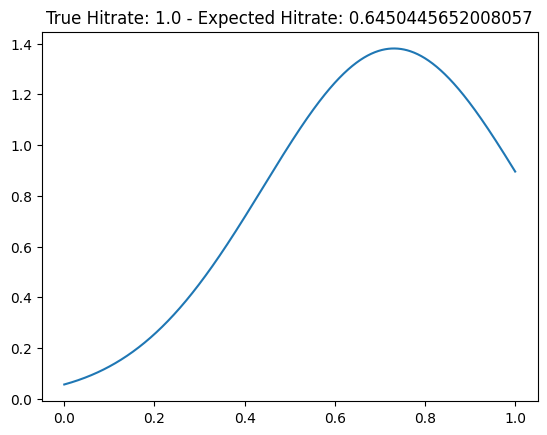

In [220]:
plt.plot(torch.linspace(0, 1, 1000), pdf)
plt.title(f"True Hitrate: {hit_rate} - Expected Hitrate: {expectation}")
plt.show()

tensor([0.0000, 0.1667, 0.3333, 0.5000, 0.6667, 0.8333, 1.0000])


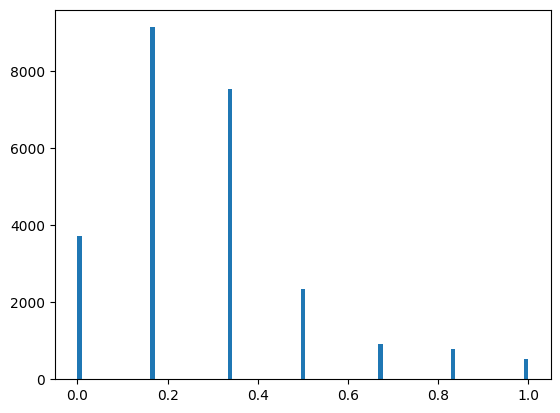

In [183]:
print(X.unique())
plt.hist(X, bins=np.linspace(0, 1, 100), align="mid")
plt.show()

In [221]:
alignment.save("fitted_alignment_delta_gt.pkl")